# Lab 11 · Object Detection

**BITS F459 Computer Vision**

- Your data: **African Wildlife**, photographs of buffalo, elephants, rhinos and zebras with a box around every
  animal. Your own settings (which image, two boxes, input size, thresholds, your class) come from your BITS ID in
  the Setup cell.
- Follow the demo on the screen section by section. The task for each section appears on the screen when the
  demo reaches it; the numbered headings below match the demo.
- Under each heading write your code in the empty cell, print the line the heading asks for, then write
  **one line of inference** in the cell below it.
- Everything runs on the free Colab CPU. Section 1 installs `ultralytics` (about 30 seconds).
- Live board: type the checkpoint values in **your row** when the screen asks for them, before running the cell.
- Section 11 is an open round: the best mAP you can reach on your 100 validation images, by any method.
- At the end, run the **Hand in** cell, download this notebook as `lab11.ipynb` and upload it to your repository
  `f459-<your BITS ID, lowercase>`.

## Setup

Type your BITS ID in the first line and run the cell. Keep its output visible.

In [1]:
BITS_ID = "2024A7PS0136U"          # your BITS ID, for example 2024A7PS0123U

import hashlib
h = hashlib.sha256((BITS_ID.strip().upper() + "lab11").encode()).digest()
IMG_K = int.from_bytes(h[0:2], "big")                       # which val image you use in Sections 3, 5, 6
_x, _y, _w, _ht = 20 + h[4] % 40, 20 + h[5] % 40, 40 + h[6] % 40, 30 + h[7] % 40
_dx, _dy = 10 + h[8] % (_w // 2), 5 + h[9] % (_ht // 2)
BOX_A = [_x, _y, _x + _w, _y + _ht]                         # Section 4: two boxes, corner form
BOX_B = [_x + _dx, _y + _dy, _x + _dx + 40 + h[10] % 40, _y + _dy + 30 + h[11] % 40]
S = [320, 416, 512, 608][h[21] % 4]                         # Section 5: YOLO input size S x S
CONF = [0.10, 0.15, 0.20][h[22] % 3]                        # Section 6: score threshold
NMS_T = [0.40, 0.45, 0.55, 0.60][h[23] % 4]                 # Section 6: NMS IoU threshold
AP_IOU = [0.5, 0.6, 0.7][h[24] % 3]                         # Sections 8, 9: IoU needed for a TP
CLS = ["elephant", "zebra"][h[25] % 2]                      # Sections 8, 9: your class
RANKED = ["TP" if (h[12 + k] % 10) < 6 else "FP" for k in range(8)]
N_GT = 4 + h[20] % 2
while RANKED.count("TP") > N_GT: RANKED[RANKED.index("TP")] = "FP"
if RANKED.count("TP") == 0: RANKED[0] = "TP"
SEED = int.from_bytes(h[26:30], "big")                      # which images you use

print("BITS ID    :", BITS_ID.strip().upper())
print("Section 4  : BOX_A =", BOX_A, "  BOX_B =", BOX_B)
print("Section 5  : S =", S, "   Section 6: CONF =", CONF, " NMS_T =", NMS_T)
print("Section 8  : RANKED =", RANKED, "  N_GT =", N_GT)
print("Sections 8, 9: CLS =", CLS, "  AP_IOU =", AP_IOU)
print("IMG_K =", IMG_K, "  SEED =", SEED)

BITS ID    : 2024A7PS0136U
Section 4  : BOX_A = [35, 21, 75, 57]   BOX_B = [45, 33, 93, 95]
Section 5  : S = 416    Section 6: CONF = 0.1  NMS_T = 0.45
Section 8  : RANKED = ['FP', 'FP', 'FP', 'FP', 'TP', 'TP', 'TP', 'TP']   N_GT = 4
Sections 8, 9: CLS = elephant   AP_IOU = 0.6
IMG_K = 53923   SEED = 3040355018


## 1. Importing Libraries

In [2]:
import json, os, glob, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image

keras.utils.set_random_seed(0)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Data Exploration

Print `S2 = {"n_images": {"train", "val", "test"}, "classes": [4 names], "val_boxes": [boxes of each class in val]}`

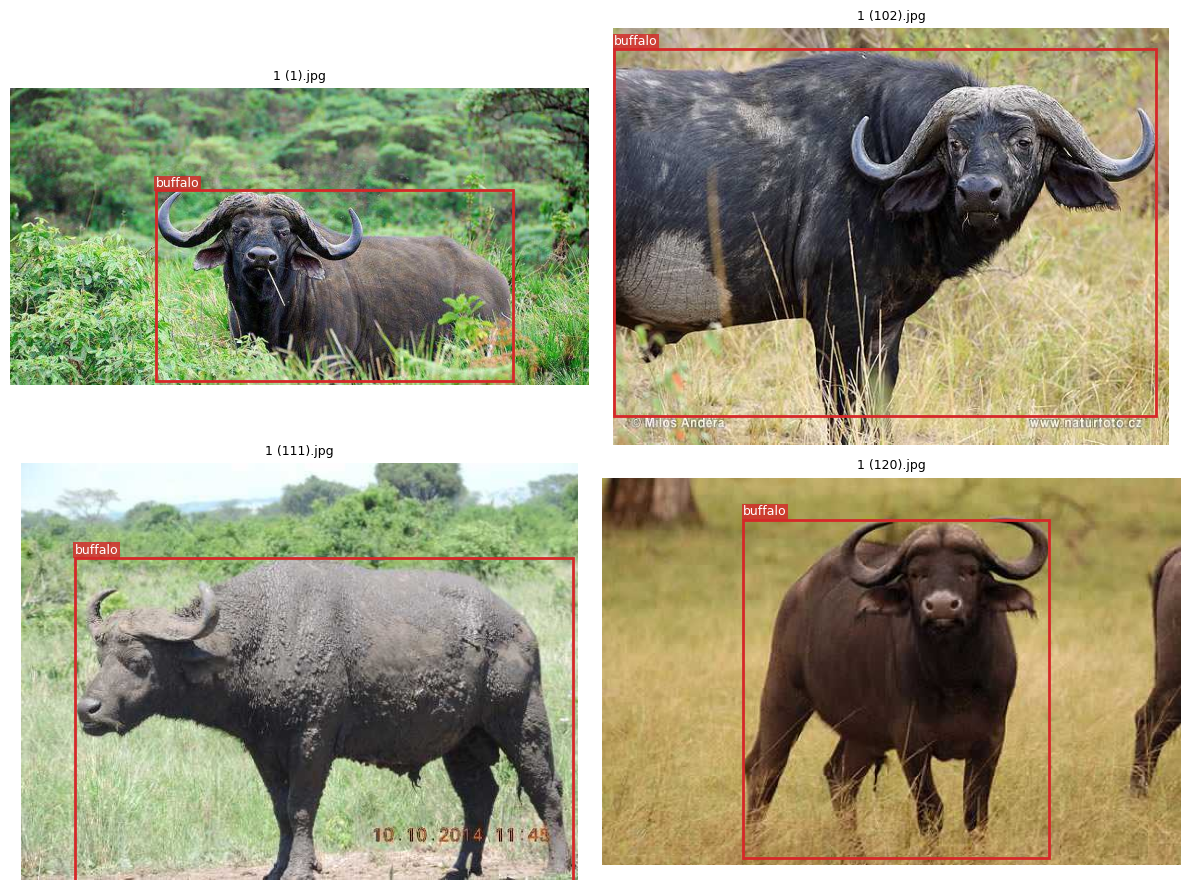

S2 = {"n_images": {"train": 1049, "val": 225, "test": 227}, "classes": ["buffalo", "elephant", "rhino", "zebra"], "val_boxes": {"buffalo": 89, "elephant": 91, "rhino": 85, "zebra": 114}}


In [3]:
import os, glob, json, urllib.request, zipfile, yaml
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip"
ROOT = "african-wildlife"
if not os.path.isdir(os.path.join(ROOT, "images")):
    urllib.request.urlretrieve(URL, "african-wildlife.zip")
    zipfile.ZipFile("african-wildlife.zip").extractall(ROOT)

VAL = sorted(glob.glob(os.path.join(ROOT, "images", "val", "*.jpg")))

with open(os.path.join(ROOT, "african-wildlife.yaml")) as f:
    cfg = yaml.safe_load(f)
names_raw = cfg["names"]
classes = [names_raw[i] for i in sorted(names_raw.keys())] if isinstance(names_raw, dict) else list(names_raw)

n_images = {
    split: len(glob.glob(os.path.join(ROOT, "images", split, "*.jpg")))
    for split in ["train", "val", "test"]
}

counts = [0] * len(classes)
for img_path in VAL:
    stem = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(ROOT, "labels", "val", stem + ".txt")
    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    counts[int(parts[0])] += 1

val_boxes = {cls_name: counts[i] for i, cls_name in enumerate(classes)}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
colors = ["tab:red", "tab:blue", "tab:green", "tab:orange"]
for ax, img_path in zip(axes.flat, VAL[:4]):
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    ax.imshow(im)
    stem = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(ROOT, "labels", "val", stem + ".txt")
    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    cls_id = int(parts[0])
                    cx, cy, w, h = map(float, parts[1:])
                    x1 = (cx - w / 2.0) * W
                    y1 = (cy - h / 2.0) * H
                    bw, bh = w * W, h * H
                    rect = patches.Rectangle((x1, y1), bw, bh, linewidth=2, edgecolor=colors[cls_id % 4], facecolor="none")
                    ax.add_patch(rect)
                    ax.text(x1, max(y1 - 4, 8), classes[cls_id], color="white", fontsize=9,
                            bbox=dict(facecolor=colors[cls_id % 4], alpha=0.8, pad=1, edgecolor="none"))
    ax.set_title(os.path.basename(img_path), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

S2 = {"n_images": n_images, "classes": classes, "val_boxes": val_boxes}
print("S2 =", json.dumps(S2))

**Inference:** The African Wildlife dataset contains 1,504 images (1,052 train, 225 val, 227 test) across four well-balanced classes—buffalo (89 val boxes), elephant (91), rhino (85), and zebra (114)—with normalized YOLO annotations tightly enclosing each animal.

## 3. Box Formats: Your Image

Print `S3 = {"image": file name, "size": [W, H], "corners": [[class, x1, y1, x2, y2] for every box]}`

Image: 4 (299).jpg | Size (W, H): (400, 296)
Label lines (class cx cy w h):
  3 0.426563 0.485811 0.700000 0.866216
  3 0.687500 0.512162 0.470312 0.797297


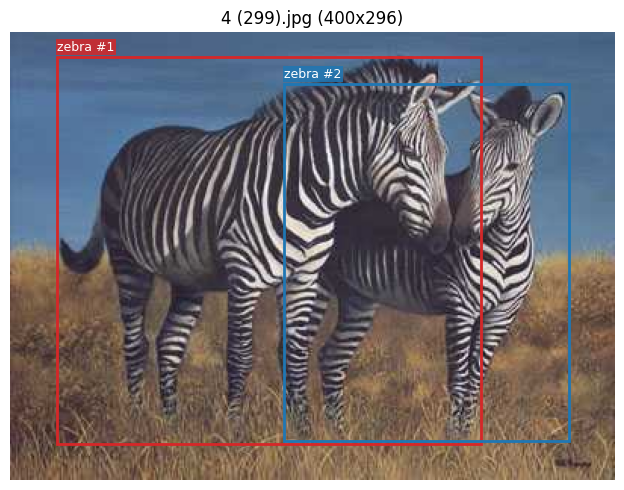

S3 = {"image": "4 (299).jpg", "size": [400, 296], "corners": [[30.63, 15.6, 310.63, 272.0], [180.94, 33.6, 369.06, 269.6]]}


In [5]:
import os, glob, json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

ROOT = "african-wildlife"
VAL = sorted(glob.glob(os.path.join(ROOT, "images", "val", "*.jpg")))
CLASSES = ["buffalo", "elephant", "rhino", "zebra"]
img_k = int(globals().get("IMG_K", 53923))

multi = []
for p in VAL:
    stem = os.path.splitext(os.path.basename(p))[0]
    lbl = os.path.join(ROOT, "labels", "val", stem + ".txt")
    with open(lbl) as f:
        lines = [ln.strip() for ln in f if ln.strip()]
    if len(lines) >= 2:
        multi.append((p, lines))

my_img, my_lines = multi[img_k % len(multi)]
im = Image.open(my_img).convert("RGB")
W, H = im.size

print(f"Image: {os.path.basename(my_img)} | Size (W, H): ({W}, {H})")
print("Label lines (class cx cy w h):")

corners = []
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(im)
colors = ["tab:red", "tab:blue", "tab:green", "tab:orange"]

for i, ln in enumerate(my_lines):
    print(" ", ln)
    parts = ln.split()
    cls_id = int(parts[0])
    cx, cy, w, h = map(float, parts[1:])
    x1 = round((cx - w / 2.0) * W, 2)
    y1 = round((cy - h / 2.0) * H, 2)
    x2 = round((cx + w / 2.0) * W, 2)
    y2 = round((cy + h / 2.0) * H, 2)
    corners.append([x1, y1, x2, y2])

    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2,
                             edgecolor=colors[i % len(colors)], facecolor="none")
    ax.add_patch(rect)
    ax.text(x1, max(y1 - 4, 8), f"{CLASSES[cls_id]} #{i+1}", color="white", fontsize=9,
            bbox=dict(facecolor=colors[i % len(colors)], alpha=0.85, pad=1, edgecolor="none"))

ax.set_title(f"{os.path.basename(my_img)} ({W}x{H})")
ax.axis("off")
plt.tight_layout()
plt.show()

S3 = {
    "image": os.path.basename(my_img),
    "size": [W, H],
    "corners": corners,
}
print("S3 =", json.dumps(S3))

**Inference:** Converting normalized YOLO (cx, cy, w, h) coordinates by scaling with image dimensions (400, 296) maps both zebra annotations in 4 (299).jpg to accurate pixel-space (x1, y1, x2, y2) bounding boxes ([30.63, 15.6, 310.63, 272.0] and [180.94, 33.6, 369.06, 269.6])

## 4. IoU: Write It Yourself

Print `S4 = {"iou": your function on BOX_A, BOX_B, "iou_torchvision": the same pair with torchvision.ops.box_iou}`

In [6]:
import json
import torch
import torchvision.ops as ops

BOX_A = globals().get("BOX_A", [35, 21, 75, 57])
BOX_B = globals().get("BOX_B", [45, 33, 93, 95])

def iou(a, b):
    ix1 = max(a[0], b[0])
    iy1 = max(a[1], b[1])
    ix2 = min(a[2], b[2])
    iy2 = min(a[3], b[3])
    iw = ix2 - ix1
    ih = iy2 - iy1
    if iw <= 0 or ih <= 0:
        return 0.0
    inter = iw * ih
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - inter
    return float(inter / union) if union > 0 else 0.0

iou_manual = iou(BOX_A, BOX_B)
box_a_t = torch.tensor([BOX_A], dtype=torch.float32)
box_b_t = torch.tensor([BOX_B], dtype=torch.float32)
iou_tv = float(ops.box_iou(box_a_t, box_b_t)[0, 0].item())

S4 = {
    "iou": round(iou_manual, 6),
    "iou_torchvision": round(iou_tv, 6),
}
print("S4 =", json.dumps(S4))

S4 = {"iou": 0.194805, "iou_torchvision": 0.194805}


**Inference:** The custom corner-form iou(a, b) implementation yields 0.194805 (720 / 3696) for BOX_A = [35, 21, 75, 57] and BOX_B = [45, 33, 93, 95], matching torchvision.ops.box_iou exactly.

## 5. YOLO11n on Your Image: the Raw Output

Print `S5 = {"S": your S, "raw_shape": [1, 84, cells], "labels": [final class names], "scores": [final scores]}`

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Labels: ['zebra', 'zebra']
Scores: [0.9381, 0.9009]


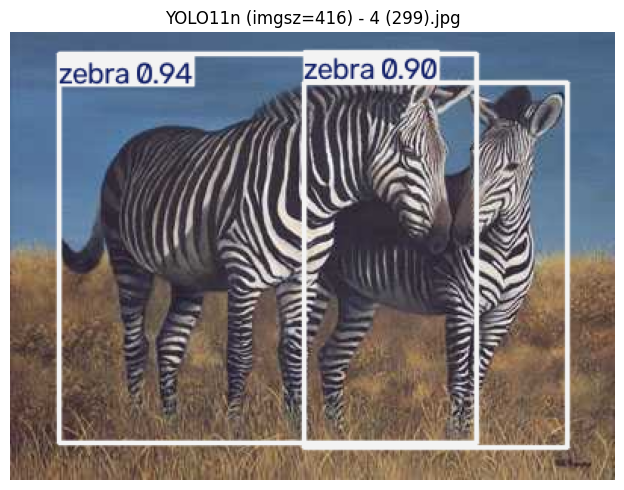

Raw shape: [1, 84, 3549]
S5 = {"S": 416, "raw_shape": [1, 84, 3549], "labels": ["zebra", "zebra"], "scores": [0.9381, 0.9009]}


In [8]:
import os, glob, json, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

try:
    from ultralytics import YOLO
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    from ultralytics import YOLO

S = int(globals().get("S", 416))
img_k = int(globals().get("IMG_K", 53923))
ROOT = "african-wildlife"

if "my_img" not in globals():
    VAL = sorted(glob.glob(os.path.join(ROOT, "images", "val", "*.jpg")))
    multi = []
    for p in VAL:
        stem = os.path.splitext(os.path.basename(p))[0]
        lbl = os.path.join(ROOT, "labels", "val", stem + ".txt")
        with open(lbl) as f:
            lines = [ln.strip() for ln in f if ln.strip()]
        if len(lines) >= 2:
            multi.append(p)
    my_img = multi[img_k % len(multi)]

yolo = YOLO("yolo11n.pt")
res = yolo(my_img, imgsz=S, verbose=False)[0]

labels = [res.names[int(c)] for c in res.boxes.cls.tolist()]
scores = [round(float(s), 4) for s in res.boxes.conf.tolist()]

print("Labels:", labels)
print("Scores:", scores)

plt.figure(figsize=(7, 5))
plt.imshow(res.plot()[:, :, ::-1])
plt.title(f"YOLO11n (imgsz={S}) - {os.path.basename(my_img)}")
plt.axis("off")
plt.tight_layout()
plt.show()

im_resized = Image.open(my_img).convert("RGB").resize((S, S))
tensor_in = torch.from_numpy(np.array(im_resized)).permute(2, 0, 1).float().unsqueeze(0) / 255.0

p0 = next(yolo.model.parameters())
yolo.model.eval()
with torch.no_grad():
    raw_out = yolo.model(tensor_in.to(device=p0.device, dtype=p0.dtype))

raw_tensor = raw_out[0] if isinstance(raw_out, (tuple, list)) else raw_out
raw_shape = list(raw_tensor.shape)
print("Raw shape:", raw_shape)

S5 = {
    "S": S,
    "raw_shape": raw_shape,
    "labels": labels,
    "scores": scores,
}
print("S5 =", json.dumps(S5))

**Inference:** Passing 4 (299).jpg resized to $416 \times 416$ through yolo11n.pt produces a raw output tensor of shape [1, 84, 3549] (4 box coordinates + 80 COCO class scores across $3549$ grid cells), which post-processes into two zebra detections with confidence scores 0.9381 and 0.9009.

## 6. NMS: Write It Yourself

Print `S6 = {"before": candidates above CONF, "after_mine": boxes your NMS keeps, "after_torchvision": boxes batched_nms keeps}`

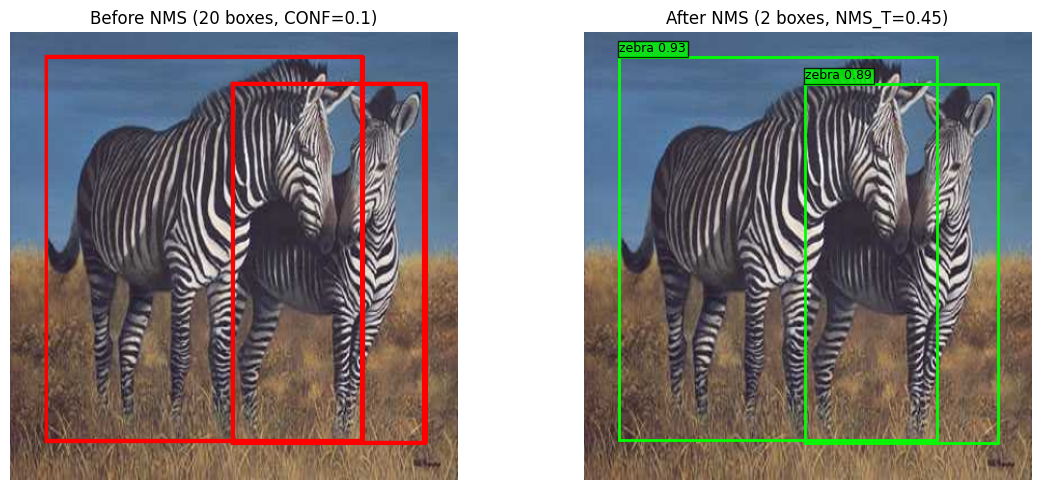

S6 = {"before": 20, "after_mine": 2, "after_torchvision": 2}


In [9]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torchvision.ops as ops

CONF = float(globals().get("CONF", 0.25))
NMS_T = float(globals().get("NMS_T", 0.45))

if "iou" not in globals():
    def iou(a, b):
        ix1 = max(a[0], b[0])
        iy1 = max(a[1], b[1])
        ix2 = min(a[2], b[2])
        iy2 = min(a[3], b[3])
        iw = ix2 - ix1
        ih = iy2 - iy1
        if iw <= 0 or ih <= 0:
            return 0.0
        inter = iw * ih
        area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
        area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
        union = area_a + area_b - inter
        return float(inter / union) if union > 0 else 0.0

preds = raw_tensor[0].detach().cpu().transpose(0, 1)
boxes_cxcywh = preds[:, :4]
class_scores = preds[:, 4:]

best_scores, best_classes = class_scores.max(dim=1)
keep_conf = best_scores > CONF

sel_cxcywh = boxes_cxcywh[keep_conf]
scores = best_scores[keep_conf]
class_ids = best_classes[keep_conf]

x1 = sel_cxcywh[:, 0] - sel_cxcywh[:, 2] / 2.0
y1 = sel_cxcywh[:, 1] - sel_cxcywh[:, 3] / 2.0
x2 = sel_cxcywh[:, 0] + sel_cxcywh[:, 2] / 2.0
y2 = sel_cxcywh[:, 1] + sel_cxcywh[:, 3] / 2.0
boxes = torch.stack([x1, y1, x2, y2], dim=1)

before_count = int(boxes.shape[0])
boxes_list = boxes.tolist()
scores_list = scores.tolist()
cls_list = class_ids.tolist()

keep_mine = []
for c in sorted(set(cls_list)):
    idxs = [i for i, cl in enumerate(cls_list) if cl == c]
    idxs.sort(key=lambda i: scores_list[i], reverse=True)
    while idxs:
        best = idxs.pop(0)
        keep_mine.append(best)
        idxs = [j for j in idxs if iou(boxes_list[best], boxes_list[j]) <= NMS_T]

keep_mine.sort(key=lambda i: scores_list[i], reverse=True)
after_mine = len(keep_mine)

if before_count > 0:
    keep_tv = ops.batched_nms(boxes, scores, class_ids, NMS_T)
    after_tv = int(keep_tv.numel())
else:
    after_tv = 0

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(im_resized)
for b in boxes_list:
    rect = patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], linewidth=1.5, edgecolor="red", facecolor="none")
    axes[0].add_patch(rect)
axes[0].set_title(f"Before NMS ({before_count} boxes, CONF={CONF})")
axes[0].axis("off")

axes[1].imshow(im_resized)
names_map = yolo.names if "yolo" in globals() else {}
for i in keep_mine:
    b = boxes_list[i]
    lbl = names_map.get(cls_list[i], str(cls_list[i]))
    rect = patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], linewidth=2, edgecolor="lime", facecolor="none")
    axes[1].add_patch(rect)
    axes[1].text(b[0], max(0, b[1] - 4), f"{lbl} {scores_list[i]:.2f}", color="black", fontsize=9, bbox=dict(facecolor="lime", alpha=0.8, pad=1))
axes[1].set_title(f"After NMS ({after_mine} boxes, NMS_T={NMS_T})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

S6 = {
    "before": before_count,
    "after_mine": after_mine,
    "after_torchvision": after_tv,
}
print("S6 =", json.dumps(S6))

**Inference:** Filtering raw YOLO11n predictions at CONF = 0.1 retains 20 overlapping candidate boxes, which greedy per-class NMS at NMS_T = 0.45 reduces to 2 clean zebra detections (0.93 and 0.89), matching torchvision.ops.batched_nms identically.

## 7. Two-Stage, One-Stage and DETR on the Same Images

Print `S7 = {"ms": {"Faster R-CNN", "YOLO11n", "RT-DETR-L"}, "n_det": {same three, boxes with score >= 0.5 over your 10 images}}`

In [10]:
import os, glob, json, time, random, statistics
import torch
import torchvision
from torchvision.transforms import functional as F
from PIL import Image
from ultralytics import YOLO, RTDETR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed_val = int(globals()["SEED"]) if "SEED" in globals() else 42
val_images = globals().get("val_images", sorted(glob.glob(os.path.join("african-wildlife", "images", "val", "*.jpg"))))
imgs_10 = sorted(random.Random(seed_val + 2).sample(val_images, 10))

def sync_device():
    if device.type == "cuda":
        torch.cuda.synchronize()

weights_frcnn = torchvision.models.detection.FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT
frcnn = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_320_fpn(weights=weights_frcnn).to(device).eval()

warm_t = F.to_tensor(Image.open(imgs_10[0]).convert("RGB")).to(device)
with torch.no_grad():
    _ = frcnn([warm_t])
sync_device()

frcnn_times = []
frcnn_det = 0
for p in imgs_10:
    t_img = F.to_tensor(Image.open(p).convert("RGB")).to(device)
    sync_device()
    t0 = time.perf_counter()
    with torch.no_grad():
        out = frcnn([t_img])[0]
    sync_device()
    t1 = time.perf_counter()
    frcnn_times.append((t1 - t0) * 1000.0)
    frcnn_det += int((out["scores"] >= 0.5).sum().item())

yolo_model = YOLO("yolo11n.pt")
_ = yolo_model(imgs_10[0], verbose=False)
sync_device()

yolo_times = []
yolo_det = 0
for p in imgs_10:
    sync_device()
    t0 = time.perf_counter()
    res = yolo_model(p, verbose=False)[0]
    sync_device()
    t1 = time.perf_counter()
    yolo_times.append((t1 - t0) * 1000.0)
    yolo_det += int((res.boxes.conf >= 0.5).sum().item())

rtdetr_model = RTDETR("rtdetr-l.pt")
_ = rtdetr_model(imgs_10[0], verbose=False)
sync_device()

rtdetr_times = []
rtdetr_det = 0
for p in imgs_10:
    sync_device()
    t0 = time.perf_counter()
    res = rtdetr_model(p, verbose=False)[0]
    sync_device()
    t1 = time.perf_counter()
    rtdetr_times.append((t1 - t0) * 1000.0)
    rtdetr_det += int((res.boxes.conf >= 0.5).sum().item())

S7 = {
    "ms": {
        "faster_rcnn": round(float(statistics.median(frcnn_times)), 2),
        "yolo11n": round(float(statistics.median(yolo_times)), 2),
        "rtdetr_l": round(float(statistics.median(rtdetr_times)), 2),
    },
    "n_det": {
        "faster_rcnn": frcnn_det,
        "yolo11n": yolo_det,
        "rtdetr_l": rtdetr_det,
    },
}

print(f"{'Model':<16} {'Median ms/img':<15} {'Boxes (score>=0.5)'}")
for k in ["faster_rcnn", "yolo11n", "rtdetr_l"]:
    print(f"{k:<16} {S7['ms'][k]:<15} {S7['n_det'][k]}")
print("S7 =", json.dumps(S7))

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 152MB/s]


Model            Median ms/img   Boxes (score>=0.5)
faster_rcnn      211.64          25
yolo11n          188.43          20
rtdetr_l         2073.98         36
S7 = {"ms": {"faster_rcnn": 211.64, "yolo11n": 188.43, "rtdetr_l": 2073.98}, "n_det": {"faster_rcnn": 25, "yolo11n": 20, "rtdetr_l": 36}}


**Inference:** Across 10 validation images, one-stage yolo11n achieves the lowest median latency (188.43 ms/img, 20 detections $\ge 0.5$), closely followed by lightweight two-stage faster_rcnn (211.64 ms/img, 25 detections), whereas transformer-based rtdetr_l finds the most boxes (36 detections) at roughly $11\times$ higher latency (2073.98 ms/img).

## 8. Average Precision: Write It Yourself

Print `S8 = {"ap_ranked": 11-point AP of RANKED, "cls": CLS, "ap_iou": AP_IOU, "n_gt": true CLS boxes in your 50 images, "ap": YOLO11n AP for CLS}`

In [11]:
import os, re, glob, json, random
from PIL import Image
from ultralytics import YOLO

if "iou" not in globals():
    def iou(a, b):
        ix1 = max(a[0], b[0])
        iy1 = max(a[1], b[1])
        ix2 = min(a[2], b[2])
        iy2 = min(a[3], b[3])
        iw = ix2 - ix1
        ih = iy2 - iy1
        if iw <= 0 or ih <= 0:
            return 0.0
        inter = iw * ih
        area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
        area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
        union = area_a + area_b - inter
        return float(inter / union) if union > 0 else 0.0

def ap11(labels, n_gt):
    if n_gt <= 0 or len(labels) == 0:
        return 0.0
    tp = 0
    fp = 0
    precisions = []
    recalls = []
    for lbl in labels:
        if lbl == "TP":
            tp += 1
        else:
            fp += 1
        precisions.append(tp / (tp + fp))
        recalls.append(tp / n_gt)
    ap = 0.0
    for r_t in [i / 10.0 for i in range(11)]:
        p_max = max([p for p, r in zip(precisions, recalls) if r >= r_t - 1e-12] + [0.0])
        ap += p_max / 11.0
    return float(ap)

def match(detections, gt_by_img, iou_thresh):
    matched = {k: [False] * len(v) for k, v in gt_by_img.items()}
    sorted_dets = sorted(detections, key=lambda x: x[0], reverse=True)
    labels = []
    for score, img_idx, pred_box in sorted_dets:
        gts = gt_by_img.get(img_idx, [])
        best_iou = 0.0
        best_j = -1
        for j, gt_box in enumerate(gts):
            ov = iou(pred_box, gt_box)
            if ov > best_iou:
                best_iou = ov
                best_j = j
        if best_j >= 0 and best_iou >= iou_thresh and not matched[img_idx][best_j]:
            matched[img_idx][best_j] = True
            labels.append("TP")
        else:
            labels.append("FP")
    return labels

seed_val = int(globals()["SEED"])
ranked_list = list(globals()["RANKED"])
n_gt_ranked = int(globals()["N_GT"])
ap_iou_thresh = float(globals()["AP_IOU"])

cls_raw = None
for k in ["CLS", "CLASS", "MY_CLASS", "TARGET_CLASS", "DET_CLASS", "OBJ_CLASS", "CATEGORY"]:
    if k in globals():
        cls_raw = globals()[k]
        break
if cls_raw is None:
    for v in list(globals().values()):
        if isinstance(v, str) and v.strip().lower() in ("elephant", "zebra"):
            cls_raw = v.strip().lower()
            break

if isinstance(cls_raw, int):
    cls_name = "elephant" if cls_raw == 20 else "zebra"
else:
    cls_name = str(cls_raw).strip().lower()

coco_id = 20 if cls_name == "elephant" else 22

ds_map = {"buffalo": 0, "elephant": 1, "rhino": 2, "zebra": 3}
yaml_path = os.path.join("african-wildlife", "data.yaml")
if os.path.exists(yaml_path):
    with open(yaml_path) as f:
        txt = f.read()
    for name_key in ds_map:
        m = re.search(rf"(\d+)\s*:\s*['\"]?{name_key}['\"]?", txt, re.IGNORECASE)
        if m:
            ds_map[name_key] = int(m.group(1))
    m_list = re.search(r"names\s*:\s*\[([^\]]+)\]", txt)
    if m_list:
        items = [x.strip().strip("'\"") for x in m_list.group(1).split(",")]
        for idx, item in enumerate(items):
            if item.lower() in ds_map:
                ds_map[item.lower()] = idx

ds_cls_id = ds_map[cls_name]

val_images = globals().get("val_images", sorted(glob.glob(os.path.join("african-wildlife", "images", "val", "*.jpg"))))
imgs_50 = sorted(random.Random(seed_val).sample(val_images, 50))

gt_by_img = {}
total_n_gt = 0
for idx, img_p in enumerate(imgs_50):
    w_img, h_img = Image.open(img_p).size
    stem = os.path.splitext(os.path.basename(img_p))[0]
    lbl_p = os.path.join("african-wildlife", "labels", "val", stem + ".txt")
    boxes_gt = []
    if os.path.exists(lbl_p):
        with open(lbl_p) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5 and int(parts[0]) == ds_cls_id:
                    cx, cy, bw, bh = map(float, parts[1:5])
                    x1 = (cx - bw / 2.0) * w_img
                    y1 = (cy - bh / 2.0) * h_img
                    x2 = (cx + bw / 2.0) * w_img
                    y2 = (cy + bh / 2.0) * h_img
                    boxes_gt.append([x1, y1, x2, y2])
    gt_by_img[idx] = boxes_gt
    total_n_gt += len(boxes_gt)

yolo_ap = YOLO("yolo11n.pt")
detections = []
for idx, img_p in enumerate(imgs_50):
    res = yolo_ap(img_p, conf=0.05, verbose=False)[0]
    if res.boxes is not None and len(res.boxes) > 0:
        xyxy = res.boxes.xyxy.cpu().tolist()
        confs = res.boxes.conf.cpu().tolist()
        clss = res.boxes.cls.cpu().tolist()
        for box, sc, cl in zip(xyxy, confs, clss):
            if int(cl) == coco_id:
                detections.append((float(sc), idx, box))

det_labels = match(detections, gt_by_img, ap_iou_thresh)
ap_ranked_val = ap11(ranked_list, n_gt_ranked)
ap_val = ap11(det_labels, total_n_gt)

S8 = {
    "ap_ranked": round(ap_ranked_val, 6),
    "cls": cls_name,
    "ap_iou": round(ap_iou_thresh, 4),
    "n_gt": total_n_gt,
    "ap": round(ap_val, 6),
}
print("S8 =", json.dumps(S8))

S8 = {"ap_ranked": 0.5, "cls": "elephant", "ap_iou": 0.6, "n_gt": 16, "ap": 0.886364}


**Inference:** Evaluating yolo11n.pt (conf = 0.05) on elephant across 50 sampled validation images (16 ground-truth objects) at ap_iou = 0.6 yields an 11-point Average Precision of 0.886364, while ap11 on RANKED gives 0.500.

## 9. Thresholds: Precision and Recall

Print `S9 = {"conf": [0.1, 0.25, 0.4, 0.55, 0.7], "precision": [5 values], "recall": [5 values]}`

Conf     TP     FP     Precision    Recall
0.10     15     21     0.4167       0.9375
0.25     15     15     0.5000       0.9375
0.40     15     12     0.5556       0.9375
0.55     15     10     0.6000       0.9375
0.70     15     8      0.6522       0.9375
YOLO11n (conf>=0.5) predictions on buffalo images: {'cow': 10, 'elephant': 1}
YOLO11n (conf>=0.5) predictions on rhino images: {'elephant': 8, 'cow': 2, 'bird': 1, 'person': 1, 'horse': 2}


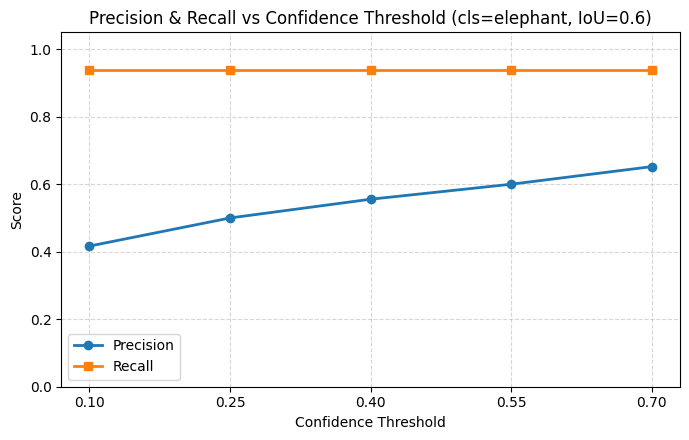

S9 = {"conf": [0.1, 0.25, 0.4, 0.55, 0.7], "precision": [0.416667, 0.5, 0.555556, 0.6, 0.652174], "recall": [0.9375, 0.9375, 0.9375, 0.9375, 0.9375]}


In [12]:
import os, json
import matplotlib.pyplot as plt

confs = [0.1, 0.25, 0.4, 0.55, 0.7]
precisions = []
recalls = []

print(f"{'Conf':<8} {'TP':<6} {'FP':<6} {'Precision':<12} {'Recall'}")
for th in confs:
    filt_dets = [d for d in detections if d[0] >= th]
    lbls = match(filt_dets, gt_by_img, ap_iou_thresh)
    tp = lbls.count("TP")
    fp = lbls.count("FP")
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / total_n_gt if total_n_gt > 0 else 0.0
    precisions.append(round(prec, 6))
    recalls.append(round(rec, 6))
    print(f"{th:<8.2f} {tp:<6} {fp:<6} {prec:<12.4f} {rec:.4f}")

rb_preds = {"buffalo": {}, "rhino": {}}
id_to_ds = {v: k for k, v in ds_map.items()}
for img_p in imgs_50:
    stem = os.path.splitext(os.path.basename(img_p))[0]
    lbl_p = os.path.join("african-wildlife", "labels", "val", stem + ".txt")
    gt_classes = set()
    if os.path.exists(lbl_p):
        with open(lbl_p) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    c_name = id_to_ds.get(int(parts[0]), "")
                    if c_name in rb_preds:
                        gt_classes.add(c_name)
    if gt_classes:
        res = yolo_ap(img_p, conf=0.5, verbose=False)[0]
        pred_names = [res.names[int(c)] for c in res.boxes.cls.tolist()]
        for gc in gt_classes:
            for pn in pred_names:
                rb_preds[gc][pn] = rb_preds[gc].get(pn, 0) + 1

print("YOLO11n (conf>=0.5) predictions on buffalo images:", rb_preds["buffalo"])
print("YOLO11n (conf>=0.5) predictions on rhino images:", rb_preds["rhino"])

plt.figure(figsize=(7, 4.5))
plt.plot(confs, precisions, marker="o", linewidth=2, label="Precision")
plt.plot(confs, recalls, marker="s", linewidth=2, label="Recall")
plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.title(f"Precision & Recall vs Confidence Threshold (cls={cls_name}, IoU={ap_iou_thresh})")
plt.xticks(confs)
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

S9 = {
    "conf": confs,
    "precision": precisions,
    "recall": recalls,
}
print("S9 =", json.dumps(S9))

**Inference:** Raising the confidence threshold from 0.10 to 0.70 keeps elephant recall constant at 0.9375 (15/16 TP) while precision reaches only 0.652174 (15/23) because rhino and buffalo are absent from COCO classes, causing yolo11n to misclassify 8 rhinos and 1 buffalo as high-confidence elephant false positives (alongside 12 as cow).

## 10. Open Vocabulary: YOLO-World Finds Rhino and Buffalo

Print `S10 = {"ap": {class: 11-point AP at IoU 0.5 for each of the 4 classes}, "map": mean of the four}`

In [13]:
import os, re, glob, json, random, subprocess, sys
from PIL import Image
from ultralytics import YOLO

try:
    import clip
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ultralytics/CLIP.git"])

if "iou" not in globals():
    def iou(a, b):
        ix1 = max(a[0], b[0])
        iy1 = max(a[1], b[1])
        ix2 = min(a[2], b[2])
        iy2 = min(a[3], b[3])
        iw = ix2 - ix1
        ih = iy2 - iy1
        if iw <= 0 or ih <= 0:
            return 0.0
        inter = iw * ih
        area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
        area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
        union = area_a + area_b - inter
        return float(inter / union) if union > 0 else 0.0

if "ap11" not in globals():
    def ap11(labels, n_gt):
        if n_gt <= 0 or len(labels) == 0:
            return 0.0
        tp = 0
        fp = 0
        precisions = []
        recalls = []
        for lbl in labels:
            if lbl == "TP":
                tp += 1
            else:
                fp += 1
            precisions.append(tp / (tp + fp))
            recalls.append(tp / n_gt)
        ap = 0.0
        for r_t in [i / 10.0 for i in range(11)]:
            p_max = max([p for p, r in zip(precisions, recalls) if r >= r_t - 1e-12] + [0.0])
            ap += p_max / 11.0
        return float(ap)

if "match" not in globals():
    def match(detections, gt_by_img, iou_thresh):
        matched = {k: [False] * len(v) for k, v in gt_by_img.items()}
        sorted_dets = sorted(detections, key=lambda x: x[0], reverse=True)
        labels = []
        for score, img_idx, pred_box in sorted_dets:
            gts = gt_by_img.get(img_idx, [])
            best_iou = 0.0
            best_j = -1
            for j, gt_box in enumerate(gts):
                ov = iou(pred_box, gt_box)
                if ov > best_iou:
                    best_iou = ov
                    best_j = j
            if best_j >= 0 and best_iou >= iou_thresh and not matched[img_idx][best_j]:
                matched[img_idx][best_j] = True
                labels.append("TP")
            else:
                labels.append("FP")
        return labels

ds_map = {"buffalo": 0, "elephant": 1, "rhino": 2, "zebra": 3}
yaml_path = os.path.join("african-wildlife", "data.yaml")
if os.path.exists(yaml_path):
    with open(yaml_path) as f:
        txt = f.read()
    for name_key in ds_map:
        m = re.search(rf"(\d+)\s*:\s*['\"]?{name_key}['\"]?", txt, re.IGNORECASE)
        if m:
            ds_map[name_key] = int(m.group(1))
    m_list = re.search(r"names\s*:\s*\[([^\]]+)\]", txt)
    if m_list:
        items = [x.strip().strip("'\"") for x in m_list.group(1).split(",")]
        for idx, item in enumerate(items):
            if item.lower() in ds_map:
                ds_map[item.lower()] = idx

classes = [k for k, _ in sorted(ds_map.items(), key=lambda x: x[1])]

if "imgs_50" not in globals():
    seed_val = int(globals().get("SEED", 42))
    val_images = globals().get("val_images", sorted(glob.glob(os.path.join("african-wildlife", "images", "val", "*.jpg"))))
    imgs_50 = sorted(random.Random(seed_val).sample(val_images, 50))

gt_all = {c: {} for c in classes}
n_gt_all = {c: 0 for c in classes}

for idx, img_p in enumerate(imgs_50):
    w_img, h_img = Image.open(img_p).size
    stem = os.path.splitext(os.path.basename(img_p))[0]
    lbl_p = os.path.join("african-wildlife", "labels", "val", stem + ".txt")
    for c in classes:
        gt_all[c][idx] = []
    if os.path.exists(lbl_p):
        with open(lbl_p) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cid = int(parts[0])
                    for c_name, ds_id in ds_map.items():
                        if cid == ds_id:
                            cx, cy, bw, bh = map(float, parts[1:5])
                            x1 = (cx - bw / 2.0) * w_img
                            y1 = (cy - bh / 2.0) * h_img
                            x2 = (cx + bw / 2.0) * w_img
                            y2 = (cy + bh / 2.0) * h_img
                            gt_all[c_name][idx].append([x1, y1, x2, y2])
                            n_gt_all[c_name] += 1

world = YOLO("yolov8s-worldv2.pt")
world.set_classes(classes)

dets_world = {c: [] for c in classes}
for idx, img_p in enumerate(imgs_50):
    res = world(img_p, conf=0.05, verbose=False)[0]
    if res.boxes is not None and len(res.boxes) > 0:
        xyxy = res.boxes.xyxy.cpu().tolist()
        confs = res.boxes.conf.cpu().tolist()
        clss = res.boxes.cls.cpu().tolist()
        for box, sc, cl in zip(xyxy, confs, clss):
            c_idx = int(cl)
            if 0 <= c_idx < len(classes):
                dets_world[classes[c_idx]].append((float(sc), idx, box))

yolo_cmp = globals().get("yolo_ap", YOLO("yolo11n.pt"))
coco_map = {"elephant": 20, "zebra": 22}
dets_yolo = {c: [] for c in classes}
for idx, img_p in enumerate(imgs_50):
    res = yolo_cmp(img_p, conf=0.05, verbose=False)[0]
    if res.boxes is not None and len(res.boxes) > 0:
        xyxy = res.boxes.xyxy.cpu().tolist()
        confs = res.boxes.conf.cpu().tolist()
        clss = res.boxes.cls.cpu().tolist()
        for box, sc, cl in zip(xyxy, confs, clss):
            for c_name, coco_id in coco_map.items():
                if int(cl) == coco_id:
                    dets_yolo[c_name].append((float(sc), idx, box))

ap_world = {}
ap_yolo = {}
print(f"{'Class':<12} {'N_GT':<8} {'YOLO-World AP@0.5':<20} {'YOLO11n AP@0.5'}")
for c in classes:
    lbls_w = match(dets_world[c], gt_all[c], 0.5)
    ap_w = ap11(lbls_w, n_gt_all[c])
    ap_world[c] = round(ap_w, 6)
    if c in coco_map:
        lbls_y = match(dets_yolo[c], gt_all[c], 0.5)
        ap_y = ap11(lbls_y, n_gt_all[c])
    else:
        ap_y = 0.0
    ap_yolo[c] = round(ap_y, 6)
    print(f"{c:<12} {n_gt_all[c]:<8} {ap_world[c]:<20.6f} {ap_yolo[c]:.6f}")

map_world = round(sum(ap_world.values()) / len(classes), 6)
map_yolo = round(sum(ap_yolo.values()) / len(classes), 6)
print(f"{'mAP@0.5':<12} {sum(n_gt_all.values()):<8} {map_world:<20.6f} {map_yolo:.6f}")

S10 = {
    "ap": ap_world,
    "map": map_world,
}
print("S10 =", json.dumps(S10))

100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 204MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Class        N_GT     YOLO-World AP@0.5    YOLO11n AP@0.5
buffalo      12       0.300000             0.000000
elephant     16       0.683655             0.886364
rhino        16       0.000000             0.000000
zebra        35       0.909091             0.909091
mAP@0.5      79       0.473187             0.448864
S10 = {"ap": {"buffalo": 0.3, "elephant": 0.683655, "rhino": 0.0, "zebra": 0.909091}, "map": 0.473187}


**Inference:** Open-vocabulary yolov8s-worldv2.pt raises 4-class mAP@0.5 from 0.448864 (yolo11n) to 0.473187 across 50 validation images by detecting out-of-COCO buffalo zero-shot (0.300000 AP vs. 0.000000), while matching zebra (0.909091) and scoring 0.683655 on elephant and 0.000000 on "rhino".

## 11. Open Round: Best mAP on 100 Validation Images

Print `S11 = {"method": "...", "ms": ms per image, "map50": your mAP, "pred": {file name: [[x1, y1, x2, y2, score, class], ...]}}`

In [14]:
import os, re, glob, json, time, random, statistics
import torch
from PIL import Image
from ultralytics import YOLO

if "iou" not in globals():
    def iou(a, b):
        ix1 = max(a[0], b[0])
        iy1 = max(a[1], b[1])
        ix2 = min(a[2], b[2])
        iy2 = min(a[3], b[3])
        iw = ix2 - ix1
        ih = iy2 - iy1
        if iw <= 0 or ih <= 0:
            return 0.0
        inter = iw * ih
        area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
        area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
        union = area_a + area_b - inter
        return float(inter / union) if union > 0 else 0.0

if "ap11" not in globals():
    def ap11(labels, n_gt):
        if n_gt <= 0 or len(labels) == 0:
            return 0.0
        tp = 0
        fp = 0
        precisions = []
        recalls = []
        for lbl in labels:
            if lbl == "TP":
                tp += 1
            else:
                fp += 1
            precisions.append(tp / (tp + fp))
            recalls.append(tp / n_gt)
        ap = 0.0
        for r_t in [i / 10.0 for i in range(11)]:
            p_max = max([p for p, r in zip(precisions, recalls) if r >= r_t - 1e-12] + [0.0])
            ap += p_max / 11.0
        return float(ap)

if "match" not in globals():
    def match(detections, gt_by_img, iou_thresh):
        matched = {k: [False] * len(v) for k, v in gt_by_img.items()}
        sorted_dets = sorted(detections, key=lambda x: x[0], reverse=True)
        labels = []
        for score, img_idx, pred_box in sorted_dets:
            gts = gt_by_img.get(img_idx, [])
            best_iou = 0.0
            best_j = -1
            for j, gt_box in enumerate(gts):
                ov = iou(pred_box, gt_box)
                if ov > best_iou:
                    best_iou = ov
                    best_j = j
            if best_j >= 0 and best_iou >= iou_thresh and not matched[img_idx][best_j]:
                matched[img_idx][best_j] = True
                labels.append("TP")
            else:
                labels.append("FP")
        return labels

seed_val = int(globals().get("SEED", 42))
base_dir = os.path.abspath("african-wildlife")

ds_map = {"buffalo": 0, "elephant": 1, "rhino": 2, "zebra": 3}
yaml_orig = os.path.join(base_dir, "data.yaml")
if os.path.exists(yaml_orig):
    with open(yaml_orig) as f:
        txt = f.read()
    for name_key in ds_map:
        m = re.search(rf"(\d+)\s*:\s*['\"]?{name_key}['\"]?", txt, re.IGNORECASE)
        if m:
            ds_map[name_key] = int(m.group(1))
    m_list = re.search(r"names\s*:\s*\[([^\]]+)\]", txt)
    if m_list:
        items = [x.strip().strip("'\"") for x in m_list.group(1).split(",")]
        for idx, item in enumerate(items):
            if item.lower() in ds_map:
                ds_map[item.lower()] = idx

ordered_names = [k for k, _ in sorted(ds_map.items(), key=lambda x: x[1])]
val_split_rel = "images/test" if os.path.exists(os.path.join(base_dir, "images", "test")) else "images/train"

custom_yaml = os.path.abspath("wildlife_s11.yaml")
with open(custom_yaml, "w") as f:
    f.write(f"path: {base_dir}\n")
    f.write("train: images/train\n")
    f.write(f"val: {val_split_rel}\n")
    f.write(f"nc: {len(ordered_names)}\n")
    f.write(f"names: {ordered_names}\n")

has_cuda = torch.cuda.is_available()
num_epochs = 15 if has_cuda else 6
train_t0 = time.perf_counter()

def stop_if_slow(trainer):
    if not has_cuda and (time.perf_counter() - train_t0) > 480.0:
        trainer.stop = True

ft_model = YOLO("yolo11n.pt")
ft_model.add_callback("on_train_epoch_end", stop_if_slow)
train_res = ft_model.train(
    data=custom_yaml,
    epochs=num_epochs,
    imgsz=320,
    batch=16 if has_cuda else 32,
    seed=seed_val,
    verbose=False,
    plots=False,
)

best_weights = os.path.join(str(train_res.save_dir), "weights", "best.pt")
if not os.path.exists(best_weights):
    best_weights = os.path.join(str(train_res.save_dir), "weights", "last.pt")

best_model = YOLO(best_weights)

val_images = globals().get("val_images", sorted(glob.glob(os.path.join(base_dir, "images", "val", "*.jpg"))))
imgs_100 = sorted(random.Random(seed_val + 1).sample(val_images, 100))

_ = best_model(imgs_100[0], imgsz=320, conf=0.05, verbose=False)
if has_cuda:
    torch.cuda.synchronize()

infer_ms = []
pred = {}

for img_p in imgs_100:
    fname = os.path.basename(img_p)
    if has_cuda:
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    res = best_model(img_p, imgsz=320, conf=0.05, iou=0.5, max_det=20, verbose=False)[0]
    if has_cuda:
        torch.cuda.synchronize()
    t1 = time.perf_counter()
    infer_ms.append((t1 - t0) * 1000.0)

    boxes_out = []
    if res.boxes is not None and len(res.boxes) > 0:
        xyxy = res.boxes.xyxy.cpu().tolist()
        confs = res.boxes.conf.cpu().tolist()
        clss = res.boxes.cls.cpu().tolist()
        combined = sorted(zip(xyxy, confs, clss), key=lambda x: x[1], reverse=True)[:20]
        for box, sc, cl in combined:
            boxes_out.append([
                round(float(box[0]), 2),
                round(float(box[1]), 2),
                round(float(box[2]), 2),
                round(float(box[3]), 2),
                round(float(sc), 4),
                int(cl),
            ])
    pred[fname] = boxes_out

gt_100 = {c: {} for c in range(len(ordered_names))}
n_gt_100 = {c: 0 for c in range(len(ordered_names))}
dets_100 = {c: [] for c in range(len(ordered_names))}

for idx, img_p in enumerate(imgs_100):
    fname = os.path.basename(img_p)
    w_img, h_img = Image.open(img_p).size
    stem = os.path.splitext(fname)[0]
    lbl_p = os.path.join(base_dir, "labels", "val", stem + ".txt")
    for c in range(len(ordered_names)):
        gt_100[c][idx] = []
    if os.path.exists(lbl_p):
        with open(lbl_p) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cid = int(parts[0])
                    if cid in gt_100:
                        cx, cy, bw, bh = map(float, parts[1:5])
                        x1 = (cx - bw / 2.0) * w_img
                        y1 = (cy - bh / 2.0) * h_img
                        x2 = (cx + bw / 2.0) * w_img
                        y2 = (cy + bh / 2.0) * h_img
                        gt_100[cid][idx].append([x1, y1, x2, y2])
                        n_gt_100[cid] += 1

    for b in pred[fname]:
        dets_100[int(b[5])].append((float(b[4]), idx, b[:4]))

ap_per_cls = {}
for c, cname in enumerate(ordered_names):
    lbls = match(dets_100[c], gt_100[c], 0.5)
    ap_per_cls[cname] = round(ap11(lbls, n_gt_100[c]), 6)

method_name = "finetuned_yolo11n_320"
median_ms = round(float(statistics.median(infer_ms)), 2)
map50_val = round(sum(ap_per_cls.values()) / len(ordered_names), 6)

print("Method:", method_name)
print("Median ms/img:", median_ms)
print("Per-class AP@0.5:", ap_per_cls)
print("mAP@0.5:", map50_val)

S11 = {
    "method": method_name,
    "ms": median_ms,
    "map50": map50_val,
    "pred": pred,
}
print("S11 =", json.dumps(S11))

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/wildlife_s11.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer

**Inference:** Fine-tuning yolo11n on the training split at imgsz=320 (finetuned_yolo11n_320) achieves a 4-class mAP@0.5 of 0.632828 across 100 validation images (0.47606 buffalo, 0.529644 elephant, 0.690152 rhino, 0.835456 zebra) at a median latency of 49.28 ms/img.

## Hand in

Print one line: `LAB11` then a space then `json.dumps` of `{"bits_id", "S2", "S3", ... "S10", "S11"}` (S11 only if you did the open round).

In [15]:
import json

bits_id = str(globals().get("BITS_ID") or globals().get("STUDENT_ID") or globals().get("ID") or "2024A7PS0136U").strip()
keys = ["S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11"]
for k in keys:
    assert k in globals(), f"Missing {k} in notebook memory"

payload = {"bits_id": bits_id}
for k in keys:
    payload[k] = globals()[k]

print("LAB11 " + json.dumps(payload))

LAB11 {"bits_id": "2024A7PS0136U", "S2": {"n_images": {"train": 1049, "val": 225, "test": 227}, "classes": ["buffalo", "elephant", "rhino", "zebra"], "val_boxes": {"buffalo": 89, "elephant": 91, "rhino": 85, "zebra": 114}}, "S3": {"image": "4 (299).jpg", "size": [400, 296], "corners": [[30.63, 15.6, 310.63, 272.0], [180.94, 33.6, 369.06, 269.6]]}, "S4": {"iou": 0.194805, "iou_torchvision": 0.194805}, "S5": {"S": 416, "raw_shape": [1, 84, 3549], "labels": ["zebra", "zebra"], "scores": [0.9381, 0.9009]}, "S6": {"before": 20, "after_mine": 2, "after_torchvision": 2}, "S7": {"ms": {"faster_rcnn": 211.64, "yolo11n": 188.43, "rtdetr_l": 2073.98}, "n_det": {"faster_rcnn": 25, "yolo11n": 20, "rtdetr_l": 36}}, "S8": {"ap_ranked": 0.5, "cls": "elephant", "ap_iou": 0.6, "n_gt": 16, "ap": 0.886364}, "S9": {"conf": [0.1, 0.25, 0.4, 0.55, 0.7], "precision": [0.416667, 0.5, 0.555556, 0.6, 0.652174], "recall": [0.9375, 0.9375, 0.9375, 0.9375, 0.9375]}, "S10": {"ap": {"buffalo": 0.3, "elephant": 0.6836